## Imports & paths

In [ ]:
from __future__ import annotations

import csv
import datetime
import json
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd()
try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass

from statistics import mean, pstdev
from typing import Optional, Sequence, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

DATA_DIR = PROJECT_ROOT / "data"
CACHE_FILE = DATA_DIR / "matches_bundle.json"
PUUIDS_CSV = PROJECT_ROOT / "Riot" / "puuids.csv"
MATCH_DATA_CSV = PROJECT_ROOT / "Riot" / "match_data.csv"

/Users/wangleyuan/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Constants & per-match stats

In [2]:
MS_PER_HOUR = 60 * 60 * 1000
MS_PER_DAY = 24 * MS_PER_HOUR
DEFAULT_RETURN_WITHIN_HOURS = 120

FULL_FEATURE_COLS = [
    "roll_kills",
    "roll_deaths",
    "roll_assists",
    "roll_kda",
    "roll_gold",
    "roll_damage",
    "roll_cs",
    "roll_vision",
    "roll_winrate",
    "n_in_window",
    "avg_gap_days_in_window",
    "std_gap_days_in_window",
    "last_gap_days",
    "matches_per_day_in_window",
    "champion_diversity",
    "losing_streak",
    "roll_avg_game_duration_sec",
]

CORE_FEATURE_COLS = [
    "roll_kda",
    "roll_winrate",
    "avg_gap_days_in_window",
    "matches_per_day_in_window",
    "champion_diversity",
    "losing_streak",
]

# Keep backward compatibility with existing cells
DEFAULT_FEATURE_COLS = FULL_FEATURE_COLS


def participant_row(match: dict, puuid: str):
    for p in match.get("info", {}).get("participants", []) or []:
        if p.get("puuid") == puuid:
            return p
    return None


def feat_dict_from_participant(p):
    if not p:
        return None
    k, d, a = (
        float(p.get("kills") or 0),
        float(p.get("deaths") or 0),
        float(p.get("assists") or 0),
    )
    deaths_safe = max(d, 1.0)
    kda = (k + a) / deaths_safe
    return {
        "kills": k,
        "deaths": d,
        "assists": a,
        "kda": kda,
        "goldEarned": float(p.get("goldEarned") or 0),
        "totalDamageDealtToChampions": float(p.get("totalDamageDealtToChampions") or 0),
        "totalMinionsKilled": float(p.get("totalMinionsKilled") or 0),
        "visionScore": float(p.get("visionScore") or 0),
        "win": 1.0 if p.get("win") else 0.0,
        "championId": float(p.get("championId") or 0),
    }


def _game_duration_sec(match: dict) -> float:
    return float(match.get("info", {}).get("gameDuration") or 0)


def _game_creation(match: dict) -> int:
    return int(match.get("info", {}).get("gameCreation") or 0)


def losing_streak_ending_at(window_matches: list, puuid: str) -> int:
    streak = 0
    for wm in reversed(window_matches):
        pr = participant_row(wm, puuid)
        fd = feat_dict_from_participant(pr)
        if not fd:
            continue
        if fd["win"] < 0.5:
            streak += 1
        else:
            break
    return streak

## Rolling-window dataset

In [3]:
def build_rows_for_player(
    puuid: str,
    matches: list,
    *,
    rolling_k: int,
    return_within_ms: float,
):
    matches = sorted(matches, key=_game_creation)
    n = len(matches)
    rows = []
    if n < 2:
        return rows

    for i in range(n - 1):
        m_cur, m_next = matches[i], matches[i + 1]
        t_cur, t_next = _game_creation(m_cur), _game_creation(m_next)
        gap_ms = float(t_next - t_cur)
        label = 1 if gap_ms <= return_within_ms else 0

        lo = max(0, i - rolling_k + 1)
        window = matches[lo : i + 1]
        flist = []
        for wm in window:
            fd = feat_dict_from_participant(participant_row(wm, puuid))
            if fd:
                flist.append(fd)
        if not flist:
            continue

        wins = [x["win"] for x in flist]
        champs = [x["championId"] for x in flist if x["championId"] > 0]
        unique_champs = len(set(champs)) if champs else 0.0

        row = {
            "puuid": puuid,
            "matchId": (m_cur.get("metadata") or {}).get("matchId"),
            "anchor_game_creation": t_cur,
            "retention_within_window": int(label),
            "roll_kills": mean(x["kills"] for x in flist),
            "roll_deaths": mean(x["deaths"] for x in flist),
            "roll_assists": mean(x["assists"] for x in flist),
            "roll_kda": mean(x["kda"] for x in flist),
            "roll_gold": mean(x["goldEarned"] for x in flist),
            "roll_damage": mean(x["totalDamageDealtToChampions"] for x in flist),
            "roll_cs": mean(x["totalMinionsKilled"] for x in flist),
            "roll_vision": mean(x["visionScore"] for x in flist),
            "roll_winrate": mean(wins),
            "n_in_window": float(len(flist)),
            "champion_diversity": unique_champs / max(len(flist), 1),
            "losing_streak": float(losing_streak_ending_at(window, puuid)),
            "roll_avg_game_duration_sec": mean(_game_duration_sec(wm) for wm in window),
            "next_gap_hours": gap_ms / MS_PER_HOUR,
        }

        if len(window) >= 2:
            gaps_days = []
            for j in range(len(window) - 1):
                g0, g1 = _game_creation(window[j]), _game_creation(window[j + 1])
                gaps_days.append((g1 - g0) / MS_PER_DAY)
            row["avg_gap_days_in_window"] = mean(gaps_days)
            row["last_gap_days"] = gaps_days[-1]
            row["std_gap_days_in_window"] = pstdev(gaps_days) if len(gaps_days) >= 2 else 0.0
        else:
            row["avg_gap_days_in_window"] = 0.0
            row["last_gap_days"] = 0.0
            row["std_gap_days_in_window"] = 0.0

        span_ms = max(_game_creation(window[-1]) - _game_creation(window[0]), 1)
        span_days = span_ms / MS_PER_DAY
        row["matches_per_day_in_window"] = (len(window) - 1) / max(span_days, 1e-6)
        rows.append(row)
    return rows


def build_modeling_dataframe(
    all_matches_by_puuid: dict,
    *,
    rolling_k: int = 5,
    return_within_hours: float = DEFAULT_RETURN_WITHIN_HOURS,
):
    return_within_ms = return_within_hours * MS_PER_HOUR
    all_rows = []
    for puuid, matches in all_matches_by_puuid.items():
        all_rows.extend(
            build_rows_for_player(
                puuid,
                matches,
                rolling_k=rolling_k,
                return_within_ms=return_within_ms,
            )
        )
    if not all_rows:
        cols = (
            ["puuid", "matchId", "anchor_game_creation", "retention_within_window"]
            + DEFAULT_FEATURE_COLS
            + ["next_gap_hours"]
        )
        return pd.DataFrame(columns=cols)
    return pd.DataFrame(all_rows)

## Training

In [4]:
def sigmoid(z: np.ndarray) -> np.ndarray:
    z = np.clip(z, -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z))


def relu(z: np.ndarray) -> np.ndarray:
    return np.maximum(0.0, z)


def relu_grad(z: np.ndarray) -> np.ndarray:
    return (z > 0).astype(np.float64)


def standard_fit(X: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    mean = X.mean(axis=0)
    scale = X.std(axis=0)
    scale = np.where(scale < 1e-12, 1.0, scale)
    return mean, scale


def standard_transform(X: np.ndarray, mean: np.ndarray, scale: np.ndarray) -> np.ndarray:
    return (X - mean) / scale


def split_by_group(
    groups: np.ndarray, test_size: float, random_state: int
) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(random_state)
    uniq = np.unique(groups)
    rng.shuffle(uniq)
    n_test_g = max(1, int(np.ceil(len(uniq) * test_size)))
    test_set = set(uniq[:n_test_g])
    train_idx = np.array([i for i, g in enumerate(groups) if g not in test_set], dtype=int)
    test_idx = np.array([i for i, g in enumerate(groups) if g in test_set], dtype=int)
    return train_idx, test_idx


def stratified_split_indices(
    y: np.ndarray, test_size: float, random_state: int
) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(random_state)
    y = np.asarray(y).ravel()
    train_parts: list[int] = []
    test_parts: list[int] = []
    for cls in (0, 1):
        idx = np.flatnonzero(y == cls)
        rng.shuffle(idx)
        n = len(idx)
        if n == 0:
            continue
        if n == 1:
            train_parts.append(int(idx[0]))
            continue
        n_test = int(np.floor(n * test_size))
        if n_test < 1:
            n_test = 1
        if n_test >= n:
            n_test = n - 1
        test_parts.extend(idx[:n_test].tolist())
        train_parts.extend(idx[n_test:].tolist())
    return np.array(train_parts, dtype=int), np.array(test_parts, dtype=int)


def balanced_sample_weights(y: np.ndarray) -> np.ndarray:
    y = np.asarray(y, dtype=int).ravel()
    n = len(y)
    counts = np.bincount(y, minlength=2).astype(np.float64)
    counts = np.maximum(counts, 1.0)
    cw = n / (2.0 * counts)
    return cw[y]


def init_mlp_params(n_in: int, n_hidden: int, rng: np.random.Generator) -> dict:
    return {
        "W1": rng.normal(scale=0.08, size=(n_in, n_hidden)),
        "b1": np.zeros((1, n_hidden), dtype=np.float64),
        "W2": rng.normal(scale=0.08, size=(n_hidden, 1)),
        "b2": np.zeros((1, 1), dtype=np.float64),
    }


def mlp_forward(X: np.ndarray, params: dict) -> dict:
    z1 = np.dot(X, params["W1"]) + params["b1"]
    a1 = relu(z1)
    z2 = np.dot(a1, params["W2"]) + params["b2"]
    p = sigmoid(z2)
    return {"X": X, "z1": z1, "a1": a1, "z2": z2, "p": p}


def binary_cross_entropy(y_true_col: np.ndarray, p_col: np.ndarray, sw_col: np.ndarray) -> float:
    eps = 1e-12
    p_safe = np.clip(p_col, eps, 1.0 - eps)
    ce = -(y_true_col * np.log(p_safe) + (1.0 - y_true_col) * np.log(1.0 - p_safe))
    return float(np.mean(sw_col * ce))


def fit_mlp_weighted_gd(
    X: np.ndarray,
    y: np.ndarray,
    sample_weight: np.ndarray,
    *,
    n_hidden: int = 6,
    lr: float = 0.04,
    n_iter: int = 4000,
    random_state: int = 42,
    l2: float = 1e-4,
) -> tuple[dict, list[float]]:
    rng = np.random.default_rng(random_state)
    n_samples, n_features = X.shape
    y_col = y.reshape(-1, 1).astype(np.float64)
    sw_col = sample_weight.reshape(-1, 1).astype(np.float64)
    sw_col = sw_col / np.mean(sw_col)

    params = init_mlp_params(n_features, n_hidden, rng)
    errors: list[float] = []

    for _ in range(n_iter):
        cache = mlp_forward(X, params)
        p = cache["p"]

        data_loss = binary_cross_entropy(y_col, p, sw_col)
        reg_loss = 0.5 * l2 * (np.sum(params["W1"] ** 2) + np.sum(params["W2"] ** 2))
        errors.append(data_loss + float(reg_loss))

        dz2 = ((p - y_col) * sw_col) / n_samples
        dW2 = np.dot(cache["a1"].T, dz2) + l2 * params["W2"]
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = np.dot(dz2, params["W2"].T)
        dz1 = da1 * relu_grad(cache["z1"])
        dW1 = np.dot(cache["X"].T, dz1) + l2 * params["W1"]
        db1 = np.sum(dz1, axis=0, keepdims=True)

        params["W1"] -= lr * dW1
        params["b1"] -= lr * db1
        params["W2"] -= lr * dW2
        params["b2"] -= lr * db2

    return params, errors


def predict_proba_mlp(X: np.ndarray, mean: np.ndarray, scale: np.ndarray, params: dict) -> np.ndarray:
    Xs = standard_transform(np.asarray(X, dtype=np.float64), mean, scale)
    return mlp_forward(Xs, params)["p"].ravel()


def basic_binary_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    yt = np.asarray(y_true, dtype=int)
    yp = np.asarray(y_pred, dtype=int)
    return {
        "accuracy": float(accuracy_score(yt, yp)),
        "precision": float(precision_score(yt, yp, zero_division=0)),
        "recall": float(recall_score(yt, yp, zero_division=0)),
        "f1": float(f1_score(yt, yp, zero_division=0)),
    }


def metrics_summary_table(meta: dict) -> pd.DataFrame:
    m = meta["metrics"]
    return pd.DataFrame(
        [
            {
                "accuracy": m["accuracy"],
                "precision": m["precision"],
                "recall": m["recall"],
                "f1": m["f1"],
            }
        ]
    )


def train_mlp_baseline(
    df: pd.DataFrame,
    feature_cols: Optional[Sequence[str]] = None,
    target_col: str = "retention_within_window",
    *,
    test_size: float = 0.25,
    random_state: int = 42,
    group_col: Optional[str] = "puuid",
    n_hidden: int = 6,
    lr: float = 0.04,
    n_iter: int = 4000,
):
    feature_cols = list(feature_cols or DEFAULT_FEATURE_COLS)
    use = df.dropna(subset=list(feature_cols) + [target_col]).copy()
    for c in feature_cols:
        use[c] = pd.to_numeric(use[c], errors="coerce")
    use = use.dropna(subset=feature_cols)
    y = use[target_col].astype(int)
    X = use[feature_cols]
    groups = use[group_col].values if group_col and group_col in use.columns else None

    if y.nunique() < 2:
        raise ValueError("Target has a single class; need more varied data.")

    if groups is not None and len(np.unique(groups)) >= 2:
        tr_i, te_i = split_by_group(groups, test_size, random_state)
        if len(tr_i) == 0 or len(te_i) == 0:
            tr_i, te_i = stratified_split_indices(y.values, test_size, random_state)
    else:
        tr_i, te_i = stratified_split_indices(y.values, test_size, random_state)

    X_train_df, X_test_df = X.iloc[tr_i], X.iloc[te_i]
    y_train, y_test = y.iloc[tr_i], y.iloc[te_i]

    X_train_m = np.asarray(X_train_df, dtype=np.float64)
    y_train_m = np.asarray(y_train, dtype=int)
    mean, scale = standard_fit(X_train_m)
    X_train_s = standard_transform(X_train_m, mean, scale)

    sw = balanced_sample_weights(y_train_m)
    params, errors = fit_mlp_weighted_gd(
        X_train_s,
        y_train_m,
        sw,
        n_hidden=n_hidden,
        lr=lr,
        n_iter=n_iter,
        random_state=random_state,
    )

    X_test_m = np.asarray(X_test_df, dtype=np.float64)
    proba = predict_proba_mlp(X_test_m, mean, scale, params)
    pred = (proba >= 0.5).astype(int)

    metrics = basic_binary_metrics(y_test.values, pred)

    retention_model = {
        "mean": mean,
        "scale": scale,
        "params": params,
        "feature_cols": feature_cols,
        "n_hidden": n_hidden,
    }
    meta = {
        "metrics": metrics,
        "n_train": int(len(y_train)),
        "n_test": int(len(y_test)),
        "errors": errors,
    }
    return retention_model, meta, use.loc[X_train_df.index], use.loc[X_test_df.index]

## Cache & Riot API

API mode uses quota; save bundle below after a successful fetch.

In [5]:
def get_riot_api_key() -> str:
    key = os.environ.get("RIOT_API_KEY", "").strip()
    if not key:
        raise RuntimeError("Set environment variable RIOT_API_KEY (do not commit it).")
    return key


def save_matches_bundle(all_matches_by_puuid: dict, path: Union[str, Path]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(all_matches_by_puuid, f)


def load_matches_bundle(path: Union[str, Path]) -> dict:
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def parse_match_data_row(raw: str):
    raw = (raw or "").strip()
    if not raw:
        return None
    try:
        # match_data.csv stores Python dict strings; allow datetime.datetime(...) objects.
        val = eval(raw, {"__builtins__": {}, "datetime": datetime})
    except Exception:
        return None
    return val if isinstance(val, dict) else None


def load_matches_from_match_data_csv(
    path: Union[str, Path],
    *,
    max_players: Optional[int] = None,
) -> dict:
    out: dict[str, list[dict]] = {}
    with open(path, "r", encoding="utf-8", newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            if not row:
                continue
            puuid = str(row[0]).strip()
            if not puuid:
                continue
            if max_players is not None and puuid not in out and len(out) >= int(max_players):
                break

            matches = out.setdefault(puuid, [])
            for idx, raw_match in enumerate(row[1:]):
                rec = parse_match_data_row(raw_match)
                if not rec:
                    continue

                game_start = rec.get("game_start")
                if isinstance(game_start, datetime.datetime):
                    game_creation = int(game_start.timestamp() * 1000)
                elif isinstance(game_start, (int, float)):
                    game_creation = int(game_start)
                else:
                    continue

                participant = dict(rec)
                participant["puuid"] = puuid
                match_id = f"csv_{puuid[-8:]}_{idx}_{game_creation}"
                matches.append(
                    {
                        "metadata": {"matchId": match_id},
                        "info": {
                            "gameCreation": game_creation,
                            "gameDuration": float(rec.get("timePlayed") or 0),
                            "participants": [participant],
                        },
                    }
                )

            matches.sort(key=lambda m: m.get("info", {}).get("gameCreation") or 0)
    return out


def load_puuids_from_csv(
    path: Union[str, Path],
    *,
    max_players: Optional[int] = 20,
    delimiter: str = ",",
):
    text = Path(path).read_text(encoding="utf-8", errors="replace")
    seen, out = set(), []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        for part in line.split(delimiter):
            p = part.strip()
            if len(p) < 10:
                continue
            if p not in seen:
                seen.add(p)
                out.append(p)
                if max_players is not None and len(out) >= max_players:
                    return out
    return out


def load_riot_ids_from_txt(path: Union[str, Path]) -> list[tuple[str, str]]:
    """One Riot ID per line: GameName#tagLine (official format). Lines starting with # are skipped."""
    out: list[tuple[str, str]] = []
    for raw in Path(path).read_text(encoding="utf-8").splitlines():
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        if "#" not in line:
            continue
        game, tag = line.split("#", 1)
        game, tag = game.strip(), tag.strip()
        if game and tag:
            out.append((game, tag))
    return out


def resolve_working_match_base_url(puuid: str, headers: dict, primary_routing: str) -> str:
    """Pick a regional host where match-v5 accepts this PUUID (same logic as fetch_sorted_matches_for_puuid)."""
    order = [primary_routing] + [r for r in _REGION_FALLBACK if r != primary_routing]
    last_err = None
    for reg in order:
        base_url = f"https://{reg}.api.riotgames.com"
        try:
            recent_match_ids(puuid, 1, base_url=base_url, headers=headers)
            return base_url
        except requests.exceptions.HTTPError as e:
            last_err = e
            code = e.response.status_code if e.response is not None else None
            if code in (400, 404):
                continue
            raise
    if last_err is not None:
        raise last_err
    raise RuntimeError("No regional host accepted match-v5 for this PUUID")


def cohort_puuids_from_seed_riot_id(
    game_name: str,
    tag_line: str,
    *,
    headers: dict,
    primary_routing: str,
    max_others: int,
    scan_match_ids: int,
) -> list[str]:
    """Account-v1 → PUUID, then collect other players' PUUIDs from recent match JSON (no manual list)."""
    base_acct = f"https://{primary_routing}.api.riotgames.com"
    seed = puuid_from_riot_id(game_name, tag_line, base_url=base_acct, headers=headers)
    base_m = resolve_working_match_base_url(seed, headers, primary_routing)
    mids = recent_match_ids(seed, min(scan_match_ids, 100), base_url=base_m, headers=headers) or []
    others: list[str] = []
    seen = {seed}
    for mid in mids:
        m = match_detail(mid, base_url=base_m, headers=headers)
        for p in m.get("info", {}).get("participants") or []:
            pid = p.get("puuid")
            if pid and pid not in seen:
                seen.add(pid)
                others.append(pid)
                if len(others) >= max_others:
                    return [seed] + others
    return [seed] + others


def riot_get(path: str, *, base_url: str, headers: dict, params: Optional[dict] = None):
    r = requests.get(base_url + path, headers=headers, params=params or {}, timeout=30)
    r.raise_for_status()
    return r.json()


def puuid_from_riot_id(game_name: str, tag_line: str, *, base_url: str, headers: dict) -> str:
    from urllib.parse import quote

    gn, tl = quote(game_name, safe=""), quote(tag_line, safe="")
    data = riot_get(f"/riot/account/v1/accounts/by-riot-id/{gn}/{tl}", base_url=base_url, headers=headers)
    return str(data["puuid"])


def recent_match_ids(puuid: str, count: int, *, base_url: str, headers: dict):
    return riot_get(
        f"/lol/match/v5/matches/by-puuid/{puuid}/ids",
        base_url=base_url,
        headers=headers,
        params={"count": count},
    )


def match_detail(match_id: str, *, base_url: str, headers: dict):
    return riot_get(f"/lol/match/v5/matches/{match_id}", base_url=base_url, headers=headers)


_REGION_FALLBACK = ("americas", "europe", "asia", "sea")


def compute_max_fetch_count_under_rate_limit(
    *,
    n_players: int,
    scan_match_ids: int = 0,
    account_calls: int = 0,
    cap_2min: int = 100,
    safety_margin: int = 8,
    min_fetch: int = 3,
) -> int:
    """Conservative fetch_count cap under Riot's 100 requests / 2 min limit."""
    n_players = max(int(n_players), 1)
    overhead = max(int(scan_match_ids), 0) + max(int(account_calls), 0) + 2
    budget = max(int(cap_2min) - int(safety_margin) - overhead, 1)
    fetch = max(1, budget // n_players - 1)
    return max(int(min_fetch), int(fetch))


def fetch_sorted_matches_for_puuid(
    puuid: str, *, fetch_count: int, headers: dict, primary_routing: str = "americas"
):
    """Try primary regional host first, then others — match-v5 is regional; wrong host → 400."""
    order = [primary_routing] + [r for r in _REGION_FALLBACK if r != primary_routing]
    last_err = None
    for reg in order:
        base_url = f"https://{reg}.api.riotgames.com"
        try:
            mids = recent_match_ids(puuid, fetch_count, base_url=base_url, headers=headers)
            mids = mids or []
            matches = [match_detail(mid, base_url=base_url, headers=headers) for mid in mids]
            matches.sort(key=lambda m: m.get("info", {}).get("gameCreation") or 0)
            if reg != primary_routing:
                print(f"note: used routing '{reg}' (not '{primary_routing}') for PUUID ...{puuid[-6:]}")
            return matches
        except requests.exceptions.HTTPError as e:
            last_err = e
            code = e.response.status_code if e.response is not None else None
            if code in (400, 404):
                continue
            raise
    if last_err is not None:
        raise last_err
    return []


def collect_matches_bundle(
    *,
    riot_ids: Optional[list] = None,
    puuids: Optional[list] = None,
    fetch_count: int = 25,
    routing: str = "americas",
):
    api_key = get_riot_api_key()
    base_url = f"https://{routing}.api.riotgames.com"
    headers = {"X-Riot-Token": api_key}
    out = {}
    if puuids:
        for puuid in puuids:
            try:
                out[puuid] = fetch_sorted_matches_for_puuid(
                    puuid,
                    fetch_count=fetch_count,
                    headers=headers,
                    primary_routing=routing,
                )
            except requests.exceptions.HTTPError as e:
                code = e.response.status_code if e.response is not None else "?"
                print(f"skip PUUID ...{puuid[-8:]} HTTP {code}")
                continue
    if riot_ids:
        for gn, tl in riot_ids:
            puuid = puuid_from_riot_id(gn, tl, base_url=base_url, headers=headers)
            out[puuid] = fetch_sorted_matches_for_puuid(
                puuid,
                fetch_count=fetch_count,
                headers=headers,
                primary_routing=routing,
            )
    return out

## Config

In [6]:
ROUTING = "americas"
MODE = "match_data_csv"

FETCH_COUNT = 10  # upper bound
ROLLING_K = 5
RETURN_WITHIN_HOURS = DEFAULT_RETURN_WITHIN_HOURS

# Used when USE_RIOT_IDS_FILE is False or file missing
RIOT_IDS = [
    ("背后猛c美羊羊", "UwU"),
]

RIOT_IDS_FILE = DATA_DIR / "riot_ids.txt"
USE_RIOT_IDS_FILE = False  # True: load from RIOT_IDS_FILE
AUTO_COHORT_FROM_MATCHES = True
MAX_COHORT_OTHERS = 2
COHORT_SCAN_MATCHES = 5  # how many recent match IDs to scan for teammates

MAX_RIOT_IDS = None
MAX_PLAYERS_FROM_CSV = 10

# Riot app limits: 20 requests / 1s and 100 requests / 2min
RATE_LIMIT_2MIN = 100
RATE_LIMIT_SAFETY_MARGIN = 8
MIN_FETCH_COUNT = 3

## Load matches

In [7]:
all_matches_by_puuid = {}

if MODE == "match_data_csv":
    if not MATCH_DATA_CSV.is_file():
        raise FileNotFoundError(f"Missing {MATCH_DATA_CSV}")
    all_matches_by_puuid = load_matches_from_match_data_csv(MATCH_DATA_CSV)
elif MODE == "cache":
    if not CACHE_FILE.is_file():
        raise FileNotFoundError(
            f"Missing {CACHE_FILE}. Use MODE='api' once and save_matches_bundle, or add a JSON file."
        )
    all_matches_by_puuid = load_matches_bundle(CACHE_FILE)
elif MODE == "api":
    _ = get_riot_api_key()
    headers = {"X-Riot-Token": get_riot_api_key()}

    if USE_RIOT_IDS_FILE and RIOT_IDS_FILE.is_file():
        riot_ids_use = load_riot_ids_from_txt(RIOT_IDS_FILE)
        print(f"loaded {len(riot_ids_use)} Riot IDs from {RIOT_IDS_FILE}")
    else:
        riot_ids_use = list(RIOT_IDS)
        if USE_RIOT_IDS_FILE:
            print(f"note: {RIOT_IDS_FILE} not found; using RIOT_IDS in Config")

    if MAX_RIOT_IDS is not None:
        riot_ids_use = riot_ids_use[: int(MAX_RIOT_IDS)]
        print(
            f"auto slice: using {len(riot_ids_use)} Riot IDs (MAX_RIOT_IDS={MAX_RIOT_IDS})"
        )

    if AUTO_COHORT_FROM_MATCHES:
        if not riot_ids_use:
            raise ValueError("Set RIOT_IDS[0] or provide riot_ids.txt for cohort mode")
        gn, tl = riot_ids_use[0]
        print(f"cohort: scanning recent matches for teammates of {gn}#{tl} ...")
        puuids = cohort_puuids_from_seed_riot_id(
            gn,
            tl,
            headers=headers,
            primary_routing=ROUTING,
            max_others=MAX_COHORT_OTHERS,
            scan_match_ids=COHORT_SCAN_MATCHES,
        )
        print(f"cohort: {len(puuids)} players (you + up to {MAX_COHORT_OTHERS} others)")
        effective_fetch_count = min(
            FETCH_COUNT,
            compute_max_fetch_count_under_rate_limit(
                n_players=len(puuids),
                scan_match_ids=COHORT_SCAN_MATCHES,
                account_calls=1,
                cap_2min=RATE_LIMIT_2MIN,
                safety_margin=RATE_LIMIT_SAFETY_MARGIN,
                min_fetch=MIN_FETCH_COUNT,
            ),
        )
        print(f"rate-limit cap: fetch_count={effective_fetch_count} (requested {FETCH_COUNT})")
        all_matches_by_puuid = collect_matches_bundle(
            puuids=puuids, fetch_count=effective_fetch_count, routing=ROUTING
        )
    else:
        effective_fetch_count = min(
            FETCH_COUNT,
            compute_max_fetch_count_under_rate_limit(
                n_players=max(len(riot_ids_use), 1),
                account_calls=len(riot_ids_use),
                cap_2min=RATE_LIMIT_2MIN,
                safety_margin=RATE_LIMIT_SAFETY_MARGIN,
                min_fetch=MIN_FETCH_COUNT,
            ),
        )
        print(f"rate-limit cap: fetch_count={effective_fetch_count} (requested {FETCH_COUNT})")
        all_matches_by_puuid = collect_matches_bundle(
            riot_ids=riot_ids_use, fetch_count=effective_fetch_count, routing=ROUTING
        )
elif MODE == "api_puuids_csv":
    _ = get_riot_api_key()
    puuids = load_puuids_from_csv(PUUIDS_CSV, max_players=MAX_PLAYERS_FROM_CSV)
    if MAX_PLAYERS_FROM_CSV is not None:
        print(
            f"auto slice: using first {len(puuids)} PUUIDs (MAX_PLAYERS_FROM_CSV={MAX_PLAYERS_FROM_CSV})"
        )
    else:
        print(f"loaded {len(puuids)} unique PUUIDs from CSV (no cap)")
    effective_fetch_count = min(
        FETCH_COUNT,
        compute_max_fetch_count_under_rate_limit(
            n_players=max(len(puuids), 1),
            cap_2min=RATE_LIMIT_2MIN,
            safety_margin=RATE_LIMIT_SAFETY_MARGIN,
            min_fetch=MIN_FETCH_COUNT,
        ),
    )
    print(f"rate-limit cap: fetch_count={effective_fetch_count} (requested {FETCH_COUNT})")
    all_matches_by_puuid = collect_matches_bundle(
        puuids=puuids, fetch_count=effective_fetch_count, routing=ROUTING
    )
else:
    raise ValueError(MODE)

print("players:", len(all_matches_by_puuid))
print({p[:12] + "...": len(m) for p, m in list(all_matches_by_puuid.items())[:5]})
if len(all_matches_by_puuid) == 0:
    print(
        "WARNING: no match data. CSV PUUIDs may be invalid/expired or not LoL; try MODE='api' with your RIOT_IDS, or a fresh PUUID list from Riot Account API."
    )

players: 280
{'J8sJe6LfniGY...': 20, 'nsmK2BNffcp-...': 12, 'nY-tW8VSjBLV...': 20, 'Wa_HfFq5JGOP...': 20, 'XXFNh_5jF6FH...': 20}


## Build dataframe

In [8]:
df = build_modeling_dataframe(
    all_matches_by_puuid,
    rolling_k=ROLLING_K,
    return_within_hours=RETURN_WITHIN_HOURS,
)
print("rows:", len(df), "features:", len(FULL_FEATURE_COLS))
df.head()

rows: 5237 features: 17


,puuid,matchId,anchor_game_creation,retention_within_window,roll_kills,roll_deaths,roll_assists,roll_kda,roll_gold,roll_damage,...,roll_winrate,n_in_window,champion_diversity,losing_streak,roll_avg_game_duration_sec,next_gap_hours,avg_gap_days_in_window,last_gap_days,std_gap_days_in_window,matches_per_day_in_window
0,J8sJe6LfniGYBt54B4njFFzo_7uO0fugyDW7E_GsFjNNp7...,csv_73v7i9ZQ_19_1768251142911,1768251142911,1,9.000000,17.0,25.000000,2.000000,12819.000000,21402.000000,...,0.000000,1.0,1.0,1.0,1072.000000,24.224780,0.000000,0.000000,0.000000,0.000000
1,J8sJe6LfniGYBt54B4njFFzo_7uO0fugyDW7E_GsFjNNp7...,csv_73v7i9ZQ_18_1768338352118,1768338352118,1,10.000000,17.5,25.500000,2.027778,13211.000000,23143.500000,...,0.500000,2.0,1.0,0.0,1115.500000,0.405121,1.009366,1.009366,0.000000,0.990721
2,J8sJe6LfniGYBt54B4njFFzo_7uO0fugyDW7E_GsFjNNp7...,csv_73v7i9ZQ_17_1768339810553,1768339810553,1,12.333333,18.0,24.333333,2.036062,14121.333333,27474.666667,...,0.333333,3.0,1.0,1.0,1183.333333,6.859967,0.513123,0.016880,0.496243,1.948851
3,J8sJe6LfniGYBt54B4njFFzo_7uO0fugyDW7E_GsFjNNp7...,csv_73v7i9ZQ_16_1768364506435,1768364506435,1,12.250000,15.5,26.000000,2.870797,13903.500000,27809.250000,...,0.500000,4.0,1.0,0.0,1168.500000,0.414575,0.437359,0.285832,0.419108,2.286450
4,J8sJe6LfniGYBt54B4njFFzo_7uO0fugyDW7E_GsFjNNp7...,csv_73v7i9ZQ_15_1768365998905,1768365998905,1,12.400000,15.0,25.000000,2.819714,13728.600000,27775.000000,...,0.400000,5.0,1.0,1.0,1138.800000,0.459601,0.332338,0.017274,0.405989,3.008985


## Sanity Checks

Before model fitting, verify dataset size, player coverage, label balance, and per-player row counts.

In [9]:
if len(df) == 0:
    print("No rows available for sanity checks.")
else:
    print("rows:", len(df))
    print("players:", df["puuid"].nunique())
    print("label counts:")
    print(df["retention_within_window"].value_counts().sort_index())

    rows_per_player = df.groupby("puuid").size()
    print("\nrows per player:")
    print(rows_per_player.describe())

    # Optional quick view of smallest/largest player histories
    print("\nrows per player (sample):")
    display(rows_per_player.sort_values().head(5).to_frame("rows").rename_axis("puuid"))
    display(rows_per_player.sort_values(ascending=False).head(5).to_frame("rows").rename_axis("puuid"))

rows: 5237
players: 280
label counts:
retention_within_window
0     325
1    4912
Name: count, dtype: int64

rows per player:
count    280.000000
mean      18.703571
std        1.832010
min        2.000000
25%       19.000000
50%       19.000000
75%       19.000000
max       19.000000
dtype: float64

rows per player (sample):


,rows
puuid,
VRG5urItlgXsgI23oDXG20St3-JNaEg4yhGw7GmgF8Y8kBh8YnnCj2sJn909JoHPRlWmXC9QQgEj8Q,2
XKxHP64koko2necpLrmVilGEMjYfPbX3Zo1YrC4xadJGawXO85aso2mGyJ7yUMZ3vIwvXCnoj_TUqQ,3
L48W67XavAKCBXkIUo2l5rdKcLdF9FhomjuN9L802A9GG-hGR7HhR4HQavUr455yNJE5UNQcnPMK8A,7
HuNc8eNIBkhfm0aiJvdsaswJ-9dFyFPdiLd-aeOlmQqG0ynHWOTE4IpVCUaz4YII35NFjEVkxHG-4w,8
nsmK2BNffcp--OGQAUv_Is8e4asuQ49p42arV903545Jirg6HleFkb5zckeebbGrdmNaZnbaYLqHQQ,11


,rows
puuid,
-2rVoVDGApd1_9FEPg4iqwxf8Uh_n5axmc17rSsLU2rlNqQYQqY_y17Fgya9aoodkWT42HJTzFhQrg,19
cw6JQGouexk4ch0rHcivJqjgOm0_iFVLGreaIjIRFPLcFik3RaN2f0YuCGhSsUAK-pOUZYmMO0GoaA,19
fEhfg7XQ8z05KeJKvXq1THh4AHB3gniEx78yL1esRMSnKXYSQEBLINpVNXiCNSz7oen9HHYb-K-R9g,19
f3Yig1Q6Tf-HsDhETKlrmleM4viQzcrZzhXxMr8TNIpP-X2JMkdD6J4RxOR-swJpYZbWQn16qBDdOg,19
eYSvsahnILbIYeY_-KlwPGSJR4Cu-wYb47exjKOwxQF2H1UdYq-AEbYg5J_BHVLynQqbJMu97WveoQ,19


## Return Window Diagnostics

Try multiple return windows and inspect class balance before committing to a threshold.

In [10]:
candidate_windows = [12, 24, 48, 72]
window_rows = []

for w in candidate_windows:
    df_w = build_modeling_dataframe(
        all_matches_by_puuid,
        rolling_k=ROLLING_K,
        return_within_hours=w,
    )
    counts = df_w["retention_within_window"].value_counts().to_dict() if len(df_w) > 0 else {}
    pos_ratio = float(df_w["retention_within_window"].mean()) if len(df_w) > 0 else float("nan")

    print(f"window={w}h")
    print("  rows:", len(df_w))
    print("  label counts:", counts)
    print("  positive ratio:", round(pos_ratio, 4) if pos_ratio == pos_ratio else "nan")

    window_rows.append(
        {
            "return_within_hours": w,
            "rows": len(df_w),
            "count_0": counts.get(0, 0),
            "count_1": counts.get(1, 0),
            "positive_ratio": pos_ratio,
        }
    )

window_diag_df = pd.DataFrame(window_rows)
print("\nSummary table:")
display(window_diag_df)

window=12h
  rows: 5237
  label counts: {1: 3669, 0: 1568}
  positive ratio: 0.7006
window=24h
  rows: 5237
  label counts: {1: 4253, 0: 984}
  positive ratio: 0.8121
window=48h
  rows: 5237
  label counts: {1: 4606, 0: 631}
  positive ratio: 0.8795
window=72h
  rows: 5237
  label counts: {1: 4749, 0: 488}
  positive ratio: 0.9068

Summary table:


,return_within_hours,rows,count_0,count_1,positive_ratio
0,12,5237,1568,3669,0.700592
1,24,5237,984,4253,0.812106
2,48,5237,631,4606,0.879511
3,72,5237,488,4749,0.906817


## Fit & metrics

In [11]:
def majority_baseline_metrics(y_train: pd.Series, y_test: pd.Series) -> dict:
    maj = int(y_train.value_counts().idxmax())
    y_pred = np.full(len(y_test), maj, dtype=int)
    y_true = y_test.astype(int).values
    acc = float(np.mean(y_pred == y_true))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {
        "majority_class": maj,
        "accuracy": acc,
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
    }

param_grid = [
    {"n_hidden": 4, "lr": 0.02, "n_iter": 3000},
    {"n_hidden": 6, "lr": 0.02, "n_iter": 4000},
    {"n_hidden": 6, "lr": 0.01, "n_iter": 6000},
    {"n_hidden": 8, "lr": 0.01, "n_iter": 6000},
]

runs = []
for p in param_grid:
    model_i, meta_i, train_df_i, test_df_i = train_mlp_baseline(
        df,
        feature_cols=FULL_FEATURE_COLS,
        target_col="retention_within_window",
        group_col="puuid",
        n_hidden=p["n_hidden"],
        lr=p["lr"],
        n_iter=p["n_iter"],
    )
    m_i = meta_i["metrics"]
    runs.append(
        {
            "n_hidden": p["n_hidden"],
            "lr": p["lr"],
            "n_iter": p["n_iter"],
            "accuracy": m_i["accuracy"],
            "precision": m_i["precision"],
            "recall": m_i["recall"],
            "f1": m_i["f1"],
            "final_loss": meta_i["errors"][-1],
            "model": model_i,
            "meta": meta_i,
            "train_df": train_df_i,
            "test_df": test_df_i,
        }
    )

runs_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ["model", "meta", "train_df", "test_df"]} for r in runs])
display(runs_df.sort_values("f1", ascending=False).reset_index(drop=True))

best_idx = int(runs_df["f1"].idxmax())
best = runs[best_idx]
retention_model = best["model"]
meta = best["meta"]
train_df = best["train_df"]
test_df = best["test_df"]

y_train = train_df["retention_within_window"].astype(int)
y_test = test_df["retention_within_window"].astype(int)
majority = majority_baseline_metrics(y_train, y_test)

m = meta["metrics"]
comp_df = pd.DataFrame(
    [
        {
            "mlp_accuracy": m["accuracy"],
            "mlp_precision": m["precision"],
            "mlp_recall": m["recall"],
            "mlp_f1": m["f1"],
            "majority_class": majority["majority_class"],
            "maj_accuracy": majority["accuracy"],
            "maj_precision": majority["precision"],
            "maj_recall": majority["recall"],
            "maj_f1": majority["f1"],
        }
    ]
)

display(comp_df)
print("best params:", {"n_hidden": best["n_hidden"], "lr": best["lr"], "n_iter": best["n_iter"]})
print(f"final training loss: {meta['errors'][-1]:.4f}")

,n_hidden,lr,n_iter,accuracy,precision,recall,f1,final_loss
0,8,0.01,6000,0.696018,0.953413,0.713128,0.815948,0.645050
1,4,0.02,3000,0.687596,0.946004,0.709887,0.811111,0.660371
2,6,0.02,4000,0.683002,0.950549,0.700972,0.806903,0.653643
3,6,0.01,6000,0.680704,0.947426,0.700972,0.805776,0.659693


,mlp_accuracy,mlp_precision,mlp_recall,mlp_f1,majority_class,maj_accuracy,maj_precision,maj_recall,maj_f1
0,0.696018,0.953413,0.713128,0.815948,1,0.94487,0.94487,1.0,0.971654


best params: {'n_hidden': 8, 'lr': 0.01, 'n_iter': 6000}
final training loss: 0.6451


## Plot

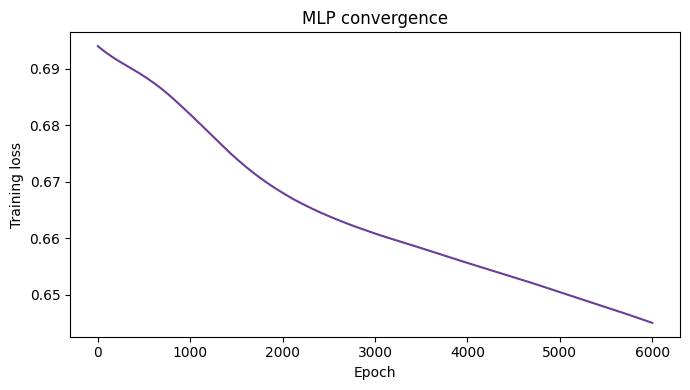

In [ ]:
errors = meta["errors"]

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(errors) + 1), errors, color="#6a3d9a")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("MLP convergence")
plt.tight_layout()
plt.show()

## Report Figure: MLP vs Baseline

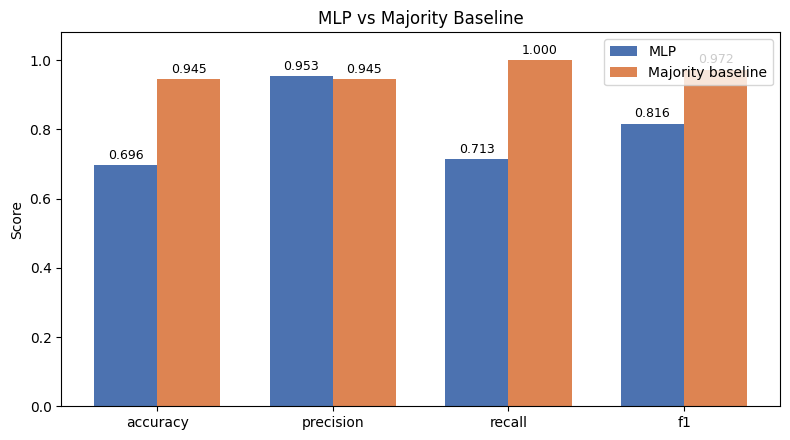

In [ ]:
metric_names = ["accuracy", "precision", "recall", "f1"]
metrics = meta["metrics"]
mlp_vals = [metrics[k] for k in metric_names]
maj_vals = [majority[k] for k in metric_names]

x = np.arange(len(metric_names))
width = 0.36

plt.figure(figsize=(8, 4.5))
plt.bar(x - width / 2, mlp_vals, width=width, label="MLP", color="#4C72B0")
plt.bar(x + width / 2, maj_vals, width=width, label="Majority baseline", color="#DD8452")

for i, v in enumerate(mlp_vals):
    plt.text(i - width / 2, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
for i, v in enumerate(maj_vals):
    plt.text(i + width / 2, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

plt.xticks(x, metric_names)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.title("MLP vs Majority Baseline")
plt.legend()
plt.tight_layout()
plt.show()